# 01 - Exploratory data analysis

What the raw inputs look like before any modelling: the sample distribution, the land-cover mix and the covariates attached to each temperature sample.

In [1]:
import sys
from pathlib import Path

# notebooks live one level below the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config
from src.data import db as db_mod

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
%matplotlib inline


In [2]:
cfg = load_config(ROOT / 'config.yaml')
engine = db_mod.get_engine(cfg)
db_mod.summarise_db(engine)

{'correlation_results': 3,
 'grid_cells': 2500,
 'group_comparison': 1,
 'idw_cv_results': 5,
 'interpolation_comparison': 2,
 'model_summary': 12,
 'regression_results': 4,
 'sample_features': 197,
 'samples': 197,
 'ward_summary': 17,
 'wards': 17}

## Temperature samples

In [3]:
samples = db_mod.read_table(engine, 'samples')
samples[['temp_c', 'lat', 'lon']].describe().round(3)

,temp_c,lat,lon
count,197.000,197.000,197.000
mean,27.653,11.016,76.958
std,2.890,0.011,0.012
min,21.202,10.995,76.933
25%,25.494,11.008,76.951
50%,27.459,11.016,76.960
75%,29.206,11.022,76.967
max,34.847,11.039,76.978


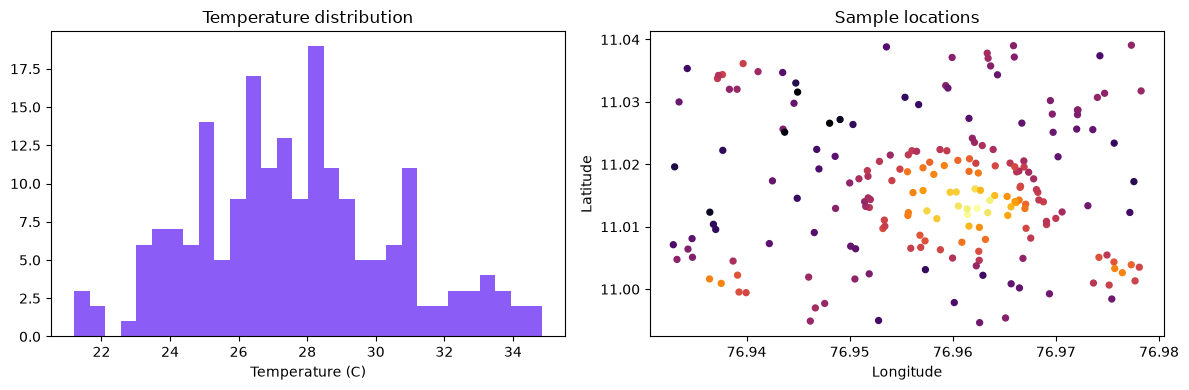

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(samples['temp_c'], bins=30, color='#8b5cf6')
axes[0].set_title('Temperature distribution')
axes[0].set_xlabel('Temperature (C)')
axes[1].scatter(samples['lon'], samples['lat'], c=samples['temp_c'],
                cmap='inferno', s=18)
axes[1].set_title('Sample locations')
axes[1].set_xlabel('Longitude'); axes[1].set_ylabel('Latitude')
plt.tight_layout(); plt.show()

## Covariates attached to each sample

In [5]:
feats = db_mod.read_table(engine, 'sample_features')
joined = samples.merge(feats, on='sample_id')
joined.groupby('landcover_class')[['temp_c', 'ndvi_mean', 'builtup_frac',
                                   'dist_water_m']].mean().round(3)

,temp_c,ndvi_mean,builtup_frac,dist_water_m
landcover_class,,,,
built_up,30.409,0.293,0.668,434.788
class_-1,22.844,0.655,0.035,268.462
grassland,28.237,0.482,0.361,1038.000
tree_cover,25.558,0.723,0.099,1152.823
water,26.891,-0.002,0.165,2.182


In [6]:
joined[['temp_c', 'ndvi_mean', 'builtup_frac', 'dist_water_m']].corr().round(3)

,temp_c,ndvi_mean,builtup_frac,dist_water_m
temp_c,1.000,-0.782,0.895,-0.242
ndvi_mean,-0.782,1.000,-0.784,0.498
builtup_frac,0.895,-0.784,1.000,-0.536
dist_water_m,-0.242,0.498,-0.536,1.000


## The analysis grid

In [7]:
grid = db_mod.read_table(engine, 'grid_cells')
print('cells:', len(grid))
grid[['ndvi_mean', 'builtup_frac', 'temp_idw', 'uhi_intensity']].describe().round(3)

cells: 2500


,ndvi_mean,builtup_frac,temp_idw,uhi_intensity
count,2500.000,2500.000,2500.000,2500.000
mean,0.642,0.150,26.333,0.700
std,0.258,0.230,2.308,2.308
min,-0.350,0.000,21.214,-4.419
25%,0.593,0.000,24.697,-0.936
50%,0.710,0.039,25.991,0.358
75%,0.801,0.207,27.600,1.967
max,0.950,1.000,34.719,9.086


**Read this.** Temperature rises with built-up fraction and falls with NDVI, which is the relationship the rest of the project quantifies.